In [1]:
import numpy as np
import os

snapshots = [99, 50, 33, 25]

fields = [
    "SubhaloMassType",
    "SubhaloSFR",
    "SubhaloGasMetallicitySfrWeighted"
]

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap}")
    print("=" * 60)

    if not os.path.exists(filename):
        print("Fajl ne postoji!")
        continue

    data = np.load(filename)

    # Broj ID-jeva
    ids = data["SubhaloID"]

    print(f"\nBroj subhaloa (ID): {len(ids)}")

    # Provera svakog polja
    lengths = []

    for field in fields:

        array = data[field]

        lengths.append(len(array))

        print(f"{field}:")
        print(f"    Oblik: {array.shape}")
        print(f"    Broj redova: {len(array)}")

    # Provera jednakog broja redova
    if len(set(lengths + [len(ids)])) == 1:

        print("\nSVI NIZOVI IMAJU ISTI BROJ REDOVA.")

    else:

        print("\nGRESKA: BROJ REDOVA SE NE POKLAPA")

    # Provera ID-jeva
    expected_ids = np.arange(len(ids))

    if np.array_equal(ids, expected_ids):

        print("ID-jevi odgovaraju indeksima u katalogu.")

    else:

        print("GRESKA: ID-jevi nisu pravilno poređani")

    # Provera da li postoje duplikati
    if len(np.unique(ids)) == len(ids):

        print("Nema dupliranih ID-jeva.")

    else:

        print("GRESKA: Postoje duplirani ID-jevi.")

    # Provera nedostajućih vrednosti
    for field in fields:

        array = data[field]

        print(
            f"{field} | NaN vrednosti:",
            np.isnan(array).sum()
        )

print("\nKraj")


SNAPSHOT 99

Broj subhaloa (ID): 4371211
SubhaloMassType:
    Oblik: (4371211, 6)
    Broj redova: 4371211
SubhaloSFR:
    Oblik: (4371211,)
    Broj redova: 4371211
SubhaloGasMetallicitySfrWeighted:
    Oblik: (4371211,)
    Broj redova: 4371211

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 50

Broj subhaloa (ID): 5127294
SubhaloMassType:
    Oblik: (5127294, 6)
    Broj redova: 5127294
SubhaloSFR:
    Oblik: (5127294,)
    Broj redova: 5127294
SubhaloGasMetallicitySfrWeighted:
    Oblik: (5127294,)
    Broj redova: 5127294

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 33

Broj subhaloa (ID): 5621338
SubhaloMassType:
    Obl

# Filtriranje: pozitivna zvezdana masa

In [2]:
import numpy as np

snapshots = [99, 50, 33, 25]

all_data = {}

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    loaded = np.load(filename)

    all_data[snap] = {
        key: loaded[key]
        for key in loaded.files
    }

    loaded.close()

    print(f'Snapshot {snap}: učitan')

Snapshot 99: učitan
Snapshot 50: učitan
Snapshot 33: učitan
Snapshot 25: učitan


In [3]:
snapshots = [99, 50, 33, 25]

filtered_data = {}

for snap in snapshots:

    print("\n" + "=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)

    data = all_data[snap]

    # Ukupan broj objekata pre filtriranja
    N_before = len(data["SubhaloID"])

    # Zvezdana masa (indeks 4)
    stellar_mass = data["SubhaloMassType"][:, 4]

    # Selekcija objekata sa pozitivnom zvezdanom masom
    mask = stellar_mass > 0

    # Broj objekata nakon filtriranja
    N_after = np.sum(mask)

    # Broj izbačenih objekata
    N_removed = N_before - N_after

    # Filtriranje svih polja istom maskom
    filtered_data[snap] = {
        field: data[field][mask]
        for field in [
            "SubhaloID",
            "SubhaloMassType",
            "SubhaloSFR",
            "SubhaloGasMetallicitySfrWeighted"
        ]
    }

    print("Broj objekata pre filtriranja:", N_before)
    print("Broj objekata nakon filtriranja:", N_after)
    print("Broj izbačenih objekata:", N_removed)

    print(
        "Procenat izbačenih objekata:",
        round(100 * N_removed / N_before, 2), "%"
    )

print("\nKraj")



SNAPSHOT 99
Broj objekata pre filtriranja: 4371211
Broj objekata nakon filtriranja: 337261
Broj izbačenih objekata: 4033950
Procenat izbačenih objekata: 92.28 %

SNAPSHOT 50
Broj objekata pre filtriranja: 5127294
Broj objekata nakon filtriranja: 492655
Broj izbačenih objekata: 4634639
Procenat izbačenih objekata: 90.39 %

SNAPSHOT 33
Broj objekata pre filtriranja: 5621338
Broj objekata nakon filtriranja: 680244
Broj izbačenih objekata: 4941094
Procenat izbačenih objekata: 87.9 %

SNAPSHOT 25
Broj objekata pre filtriranja: 5828784
Broj objekata nakon filtriranja: 836537
Broj izbačenih objekata: 4992247
Procenat izbačenih objekata: 85.65 %

Kraj


# Filtriranje: logSFR>-4

In [4]:
import numpy as np

final_data = {}

for snap in snapshots:

    data = filtered_data[snap]

    # Racunanje logSFR
    logSFR = np.full(len(data["SubhaloSFR"]), -np.inf)

    positive_sfr = data["SubhaloSFR"] > 0
    logSFR[positive_sfr] = np.log10(data["SubhaloSFR"][positive_sfr])

    # Uslov: logSFR > -4
    mask = logSFR > -4

    # Primena maske na sva polja
    final_data[snap] = {
        key: data[key][mask]
        for key in data.keys()
    }

    N_before = len(data["SubhaloID"])
    N_after = np.sum(mask)
    N_removed = N_before - N_after

    print("=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)
    print(f"Broj objekata pre dodatnog filtriranja: {N_before}")
    print(f"Broj objekata nakon dodatnog filtriranja: {N_after}")
    print(f"Broj izbacenih objekata: {N_removed}")
    print(f"Procenat izbacenih objekata: {100*N_removed/N_before:.2f} %")

SNAPSHOT 99
Broj objekata pre dodatnog filtriranja: 337261
Broj objekata nakon dodatnog filtriranja: 71575
Broj izbacenih objekata: 265686
Procenat izbacenih objekata: 78.78 %
SNAPSHOT 50
Broj objekata pre dodatnog filtriranja: 492655
Broj objekata nakon dodatnog filtriranja: 147241
Broj izbacenih objekata: 345414
Procenat izbacenih objekata: 70.11 %
SNAPSHOT 33
Broj objekata pre dodatnog filtriranja: 680244
Broj objekata nakon dodatnog filtriranja: 274398
Broj izbacenih objekata: 405846
Procenat izbacenih objekata: 59.66 %
SNAPSHOT 25
Broj objekata pre dodatnog filtriranja: 836537
Broj objekata nakon dodatnog filtriranja: 425208
Broj izbacenih objekata: 411329
Procenat izbacenih objekata: 49.17 %


# SFMS i MW-like

In [7]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]


# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

# Rezultati
TNG_populations = {}
MW_statistics = {}

for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)

    # SFMS fit pomocu Huber regresije
    X = logM.reshape(-1, 1)
    y = logSFR

    huber = HuberRegressor()
    huber.fit(X, y)

    # Odstupanje od SFMS relacije
    logSFR_fit = huber.predict(X)
    delta_logSFR = logSFR - logSFR_fit

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": data["SubhaloID"][upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": data["SubhaloID"][lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    # Izdvajanje MW-like populacije iz upper populacije
    MW_mass = protoMWmass[z]

    MW_mask = np.abs(upper["logM"] - MW_mass) <= 0.2
    MW_like = upper[MW_mask].copy()

    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": data["SubhaloID"],
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "mw_mass_like": MW_like,
        "huber": huber
    }

    # Osnovna statistika MW-like populacije
    MW_statistics[z] = {
        "N": len(MW_like),
        "median_logM": MW_like["logM"].median(),
        "median_logSFR": MW_like["logSFR"].median()
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(data['SubhaloID'])}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"MW-like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")

SNAPSHOT 99 | z = 0
Ukupan broj galaksija: 71575
Upper populacija: 68438
Lower populacija: 3137
MW-like populacija: 836
SFMS nagib: 0.8840
SFMS odsečak: -8.9508
SNAPSHOT 50 | z = 1
Ukupan broj galaksija: 147241
Upper populacija: 143950
Lower populacija: 3291
MW-like populacija: 1631
SFMS nagib: 0.9980
SFMS odsečak: -9.5499
SNAPSHOT 33 | z = 2
Ukupan broj galaksija: 274398
Upper populacija: 269569
Lower populacija: 4829
MW-like populacija: 1459
SFMS nagib: 1.0448
SFMS odsečak: -9.5911
SNAPSHOT 25 | z = 3
Ukupan broj galaksija: 425208
Upper populacija: 418428
Lower populacija: 6780
MW-like populacija: 1112
SFMS nagib: 1.0742
SFMS odsečak: -9.5490


# SFMS fit u ograničenom masenom opsegu (9 < logM < 11.2)

In [9]:
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]


# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

# Rezultati
TNG_populations = {}
MW_statistics = {}

for snap, z in snapshot_redshifts.items():

    data = final_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)
#======================================================================================================================
    


    # SFMS fit samo u ogranicenom masenom opsegu
    fit_mask = (logM > 9) & (logM < 11.2)

    X = logM[fit_mask].reshape(-1, 1)
    y = logSFR[fit_mask]

    huber = HuberRegressor()
    huber.fit(X, y)

    # Predikcija SFMS relacije za sve galaksije
    logSFR_fit = huber.predict(logM.reshape(-1, 1))

    # Odstupanje od SFMS relacije
    delta_logSFR = logSFR - logSFR_fit





    #=================================================================================================================

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": data["SubhaloID"][upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": data["SubhaloID"][lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    # Izdvajanje MW-like populacije iz upper populacije
    MW_mass = protoMWmass[z]

    MW_mask = np.abs(upper["logM"] - MW_mass) <= 0.2
    MW_like = upper[MW_mask].copy()

    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": data["SubhaloID"],
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "mw_mass_like": MW_like,
        "huber": huber
    }

    # Osnovna statistika MW-like populacije
    MW_statistics[z] = {
        "N": len(MW_like),
        "median_logM": MW_like["logM"].median(),
        "median_logSFR": MW_like["logSFR"].median()
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija: {len(data['SubhaloID'])}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"MW-like populacija: {len(MW_like)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")
#===================================================================================================
    print(f"Galaksije korišćene za SFMS fit: {len(X)}")
"""

'\nimport numpy as np\nimport pandas as pd\nfrom sklearn.linear_model import HuberRegressor\n\n\nprotoMWmass = [\n    10.68,\n    10.48,\n    10.28,\n    9.98\n]\n\n\n# Veza između snapshot-a i crvenog pomaka\nsnapshot_redshifts = {\n    99: 0,\n    50: 1,\n    33: 2,\n    25: 3\n}\n\n# Rezultati\nTNG_populations = {}\nMW_statistics = {}\n\nfor snap, z in snapshot_redshifts.items():\n\n    data = final_data[snap]\n\n    # Izvlacenje zvezdane mase i SFR-a\n    stellar_mass = data["SubhaloMassType"][:, 4]\n    sfr = data["SubhaloSFR"]\n\n    # Konverzija mase u Msun\n    mass_msun = stellar_mass * 1e10 / 0.6774\n\n    # Logaritamske vrednosti\n    logM = np.log10(mass_msun)\n    logSFR = np.log10(sfr)\n#======================================================================================================================\n\n\n\n    # SFMS fit samo u ogranicenom masenom opsegu\n    fit_mask = (logM > 9) & (logM < 11.2)\n\n    X = logM[fit_mask].reshape(-1, 1)\n    y = logSFR[fit_mask]\n\n 

# 2. SFMS

In [10]:
"""
TNG_upper_fit = {}

for snap, z in snapshot_redshifts.items():

    upper = TNG_populations[z]["upper"]

    
    X = upper["logM"].values.reshape(-1, 1)
    y = upper["logSFR"].values

    
    huber_upper = HuberRegressor()
    huber_upper.fit(X, y)

    
    logSFR_fit = huber_upper.predict(X)

    
    delta_logSFR = y - logSFR_fit

    
    upper_mask_new = delta_logSFR > -1
    lower_mask_new = delta_logSFR <= -1

    upper_new = pd.DataFrame({
        "id": upper["id"].values[upper_mask_new],
        "logM": upper["logM"].values[upper_mask_new],
        "logSFR": upper["logSFR"].values[upper_mask_new],
        "delta_logSFR": delta_logSFR[upper_mask_new]
    })

    lower_new = pd.DataFrame({
        "id": upper["id"].values[lower_mask_new],
        "logM": upper["logM"].values[lower_mask_new],
        "logSFR": upper["logSFR"].values[lower_mask_new],
        "delta_logSFR": delta_logSFR[lower_mask_new]
    })

    
    TNG_upper_fit[z] = {
        "all": upper.copy(),
        "upper": upper_new,
        "lower": lower_new,
        "huber": huber_upper
    }

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Broj galaksija u novom SFMS fit-u: {len(upper)}")
    print(f"Nova upper populacija: {len(upper_new)}")
    print(f"Nova lower populacija: {len(lower_new)}")
    print(f"SFMS nagib: {huber_upper.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber_upper.intercept_:.4f}")
"""

'\nTNG_upper_fit = {}\n\nfor snap, z in snapshot_redshifts.items():\n\n    upper = TNG_populations[z]["upper"]\n\n\n    X = upper["logM"].values.reshape(-1, 1)\n    y = upper["logSFR"].values\n\n\n    huber_upper = HuberRegressor()\n    huber_upper.fit(X, y)\n\n\n    logSFR_fit = huber_upper.predict(X)\n\n\n    delta_logSFR = y - logSFR_fit\n\n\n    upper_mask_new = delta_logSFR > -1\n    lower_mask_new = delta_logSFR <= -1\n\n    upper_new = pd.DataFrame({\n        "id": upper["id"].values[upper_mask_new],\n        "logM": upper["logM"].values[upper_mask_new],\n        "logSFR": upper["logSFR"].values[upper_mask_new],\n        "delta_logSFR": delta_logSFR[upper_mask_new]\n    })\n\n    lower_new = pd.DataFrame({\n        "id": upper["id"].values[lower_mask_new],\n        "logM": upper["logM"].values[lower_mask_new],\n        "logSFR": upper["logSFR"].values[lower_mask_new],\n        "delta_logSFR": delta_logSFR[lower_mask_new]\n    })\n\n\n    TNG_upper_fit[z] = {\n        "all": uppe

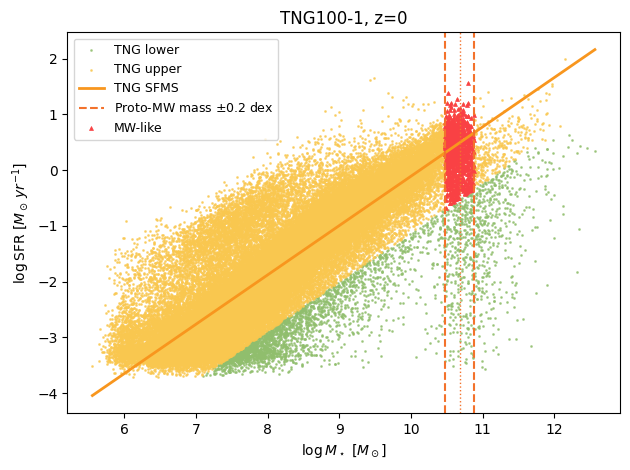

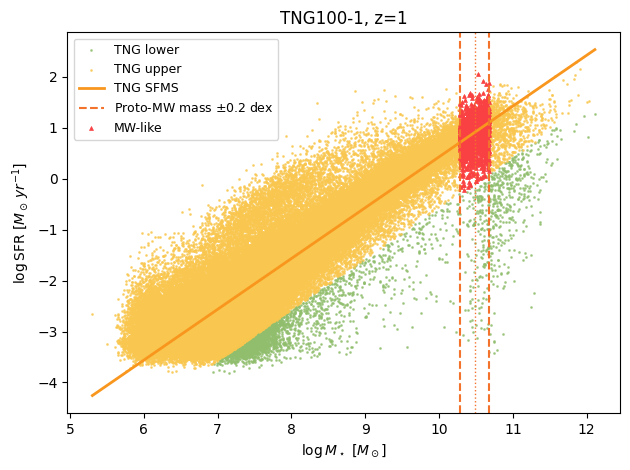

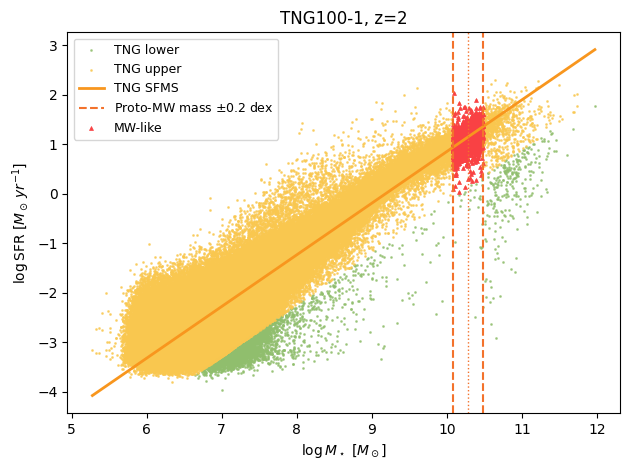

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_11656\1689410732.py:93: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


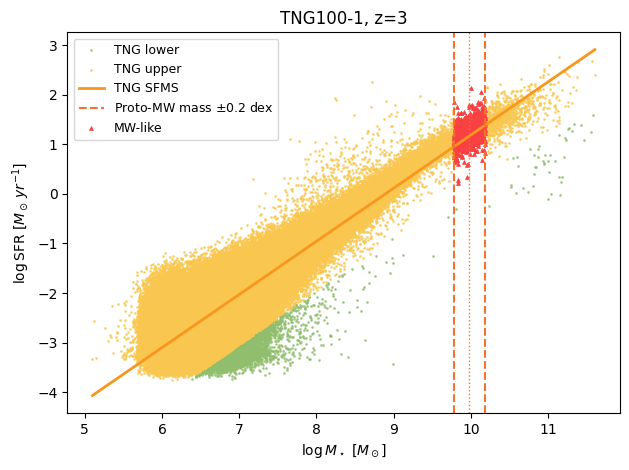

In [12]:
import matplotlib.pyplot as plt

for z in snapshot_redshifts.values():

    upper = TNG_populations[z]["upper"]
    lower = TNG_populations[z]["lower"]
    mw_mass_like = TNG_populations[z]["mw_mass_like"]
    tng_huber = TNG_populations[z]["huber"]
    df_sfms = TNG_populations[z]["all"]

    plt.figure()

    # TNG lower
    plt.scatter(
        lower["logM"],
        lower["logSFR"],
        s=1,
        alpha=0.7,
        color="#90be6d",
        label="TNG lower"
    )

    # TNG upper
    plt.scatter(
        upper["logM"],
        upper["logSFR"],
        s=1,
        alpha=0.7,
        color="#f9c74f",
        label="TNG upper"
    )

    # TNG SFMS
    x_tng = np.linspace(
        df_sfms["logM"].min(),
        df_sfms["logM"].max(),
        200
    )

    y_tng = tng_huber.predict(
        x_tng.reshape(-1, 1)
    )

    plt.plot(
        x_tng,
        y_tng,
        color="#f8961e",
        linestyle="-",
        linewidth=2,
        label="TNG SFMS"
    )

    # MW maseni opseg
    plt.axvline(
        protoMWmass[z] - 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        protoMWmass[z] + 0.2,
        color="#f3722c",
        linestyle="--",
        linewidth=1.5,
        label=r"Proto-MW mass $\pm0.2$ dex"
    )

    # Proto-MW masa
    plt.axvline(
        protoMWmass[z],
        color="#f3722c",
        linestyle=":",
        linewidth=1
    )

    # MW-like galaksije
    plt.scatter(
        mw_mass_like["logM"],
        mw_mass_like["logSFR"],
        marker="^",
        s=8,
        color="#f94144",
        linewidth=0.5,
        label="MW-like"
    )

    plt.xlabel(r"$\log M_\star\ [M_\odot]$")
    plt.ylabel(r"$\log \mathrm{SFR}\ [M_\odot\,yr^{-1}]$")
    plt.title(f"TNG100-1, z={z}")

    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

In [11]:
for z in snapshot_redshifts.values():

    mw_mass_like = TNG_populations[z]["mw_mass_like"]

    median_logSFR = mw_mass_like["logSFR"].median()

    p16 = np.percentile(mw_mass_like["logSFR"], 16)
    p84 = np.percentile(mw_mass_like["logSFR"], 84)

    print(
        f"z = {z}: "
        f"median logSFR = {median_logSFR:.4f}, "
        f"16–84% interval = [{p16:.4f}, {p84:.4f}]"
    )   

z = 0: median logSFR = 0.3531, 16–84% interval = [-0.1525, 0.7263]
z = 1: median logSFR = 0.9290, 16–84% interval = [0.6264, 1.1707]
z = 2: median logSFR = 1.1131, 16–84% interval = [0.8823, 1.3372]
z = 3: median logSFR = 1.2287, 16–84% interval = [1.0597, 1.4121]
